In [27]:
import pandas as pd

from common.config import IDPA_DATASET

df = pd.read_parquet(IDPA_DATASET).dropna()

In [ ]:
sample = df[df["category"] == "scenery"].sample(1)
display(sample)
sample_key = sample["key"].values[0]

# Scenery: "000001084"
# Animal: "000000845"

,url,category,key,width,height,exif,aspect_ratio,size,rms_contrast,sobel_edge_strength,canny_edge_density,box_size,gaussian_sigma,gaussian_size,motion_length,motion_angle
1189,https://www.mountainphotography.com/images/xl/...,scenery,000001084,1657.0,1800.0,"{""Image Make"": ""SONY"", ""Image Model"": ""ILCE-7R...",0.920556,5325819.0,0.187693,56.448465,0.172538,8.0,3.873707,21.0,22.0,345.831479


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import re

from common.img_output import get_original, get_blurred, get_deblurred, crop
from common.config import FIGURES_DIR

from typing import List

def show_comparison(
        key: str,
        blur_types: List[str],
        method: str = None,
        cropped: bool = False,
        is_save: bool = False
):
    if not method:
        original = mpimg.imread(get_original(key))
        blurred = [mpimg.imread(get_blurred(key, blur_type)) for blur_type in blur_types]

        if cropped:
            original = crop(original)
            blurred = [crop(el) for el in blurred]

        images = [
            {"title": "Original", "image": original},
        ]

        for i, img in enumerate(blurred):
            images.append({
                "title": f"Blurred ({blur_types[i]})" if len(blurred) > 1 else f"Deblurred {method}",
                "image": img
            })

        fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
        if len(images) == 1:
            axes = [axes]
        for i, el in enumerate(images):
            axes[i].imshow(el["image"])
            axes[i].set_title(el["title"])
            axes[i].axis('off')
        plt.show()

        if is_save:
            save_dir = FIGURES_DIR / "comparisons"
            save_dir.mkdir(parents=True, exist_ok=True)
            name = f"{key}_blurs"
            name += "_cropped.png" if cropped else ".png"
            fig.savefig(save_dir / name, bbox_inches='tight')


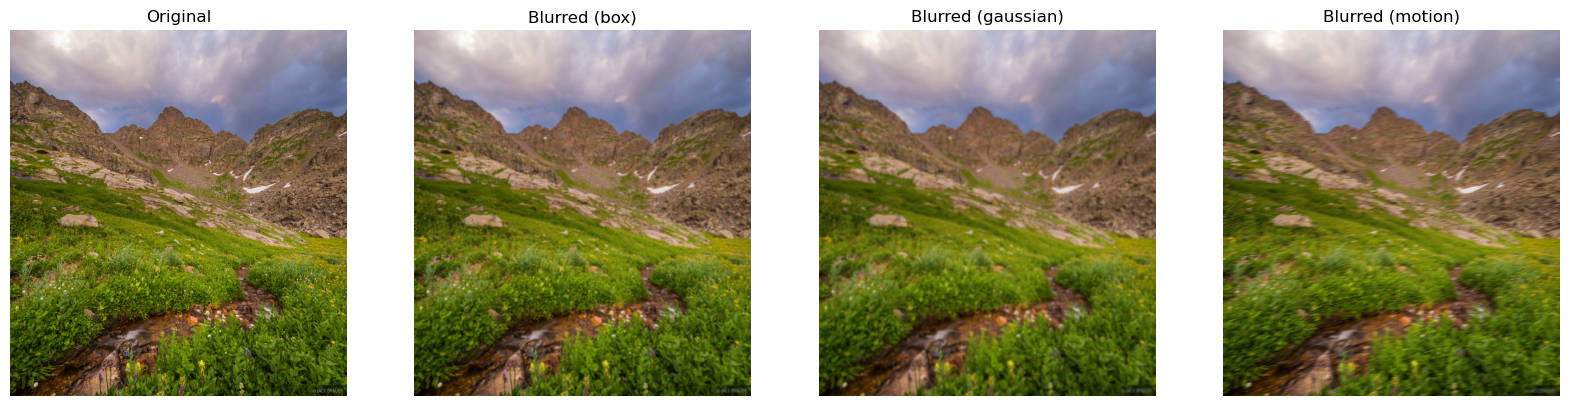

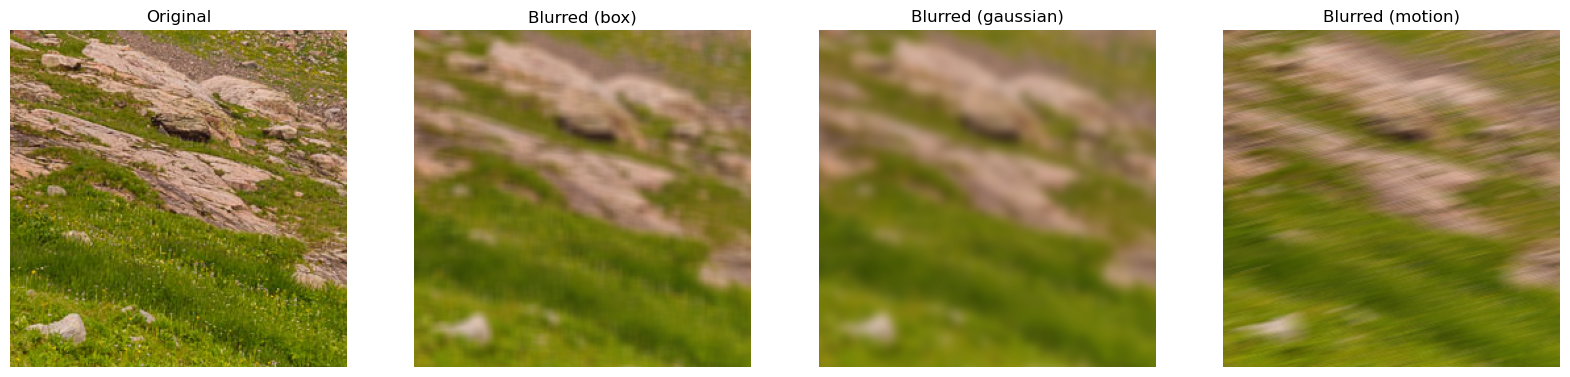

In [ ]:
from common.config import BLUR_TYPES

show_comparison(
    key=sample_key, 
    blur_types=BLUR_TYPES,
    cropped=False,
)

show_comparison(
    key=sample_key, 
    blur_types=BLUR_TYPES,
    cropped=True
)